![Banner](../../../../Images/Banner/05_geostat/09_capstones.png)

# Sexually Transmitted Infections and HIV in California Counties: Poisson Kriging in Space, Time and Across Diseases

**A geostatistical capstone on county count data: area-to-area and area-to-point Poisson kriging, Poisson cokriging and space-time Poisson kriging**

This is Capstone 7 of the geostatistics module (Part 9). It applies the three families of Poisson kriging in `geolattice.geostatistics` to county counts of chlamydia, gonorrhea and early syphilis in California from 2001 to 2021, and to HIV prevalence with its social determinants. Each family borrows strength from a different place: Poisson kriging from neighbouring counties, Poisson cokriging from other diseases in the same county, and space-time Poisson kriging from the same county in other years. The capstone asks which of these sources of information actually helps.

**Data:**

- `Data/00_shared/data_geostatistics/USA_Data/ca_stds_by_disease_county_year_sex.csv`: cases, population and rates of chlamydia, gonorrhea and early syphilis for 58 counties, 2001 to 2021, by sex.
- `Data/00_shared/data_geostatistics/USA_Data/Ca_las-sql-2026-11-14.csv`: County Health Rankings HIV cases and prevalence for 2020 to 2025, with Social Vulnerability Index themes and census shares.
- `Data/00_shared/data_geostatistics/US_COUNTY.shp`: county polygons (NAD 1983 Albers).

**Library:** `PoissonKriging`, `PointSupport`, `AreaPoissonKriging`, `multi_poisson_kriging` (`poisson_cokrige`, `fit_lmc`), `STPoissonKriging` and the space-time variogram tools.

## Overview

County rates of rare infections are unreliable in small counties. A county of 1,200 people with one case of early syphilis has a rate of 83 per 100,000; with none, its rate is zero. Poisson kriging (Goovaerts, 2005, 2006) treats each count as Poisson given an underlying risk, removes the population-dependent noise from the semivariogram, and adds an error term B·m*/n to the diagonal of the kriging system, so that small counties are smoothed towards their neighbours.

Three extensions are compared:

- **Area-to-area (ATA) and area-to-point (ATP) Poisson kriging** represent each county by a set of points inside it instead of its centroid. ATA accounts for the size and shape of counties, which matters in California, where San Bernardino County is 400 times larger than San Francisco. ATP turns county rates into a continuous risk surface whose population-weighted average reproduces the county estimate.
- **Poisson cokriging** (Payares-Garcia et al., 2024) uses other diseases counted in the same counties. HIV shares transmission routes and risk groups with syphilis and gonorrhea, so their counts carry information about HIV, including in counties where HIV counts are suppressed.
- **Space-time Poisson kriging** uses the same counties in other years. Rates of sexually transmitted infections change over years but county rankings are persistent, so the county's own history may be the best neighbour.

### Objectives

| Objective | Question | Sections |
|---|---|---|
| 1. Prepare the data | What do the files contain, which counts are suppressed, and how do the two sources line up? | 1 |
| 2. Describe | How have the three infections changed since 2001, and how strongly are counties related in space, in time and across diseases? | 2 |
| 3. Spatial structure | What do Poisson semivariograms of county rates look like with only 58 counties? | 3 |
| 4. Space | Do ATA and ATP improve on centroid Poisson kriging, and what does the risk surface look like? | 4 |
| 5. Across diseases | How much do gonorrhea and early syphilis improve HIV estimates, and what are the suppressed HIV counts likely to be? | 5 |
| 6. Time | How much does the county's own history improve the estimate of a yearly rate? | 6 |
| 7. Social determinants | Which social conditions go with HIV risk once small-number noise is removed? | 7 |

## Setup

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Inline figures, with TensorFlow blocked so optional deep-learning backends stay unloaded.
%matplotlib inline
import sys, time, warnings
warnings.filterwarnings("ignore")
sys.modules.setdefault("tensorflow", None)

from pathlib import Path

# County polygons, distance tools, and the Poisson kriging estimators.
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats
from scipy.optimize import least_squares
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist

import geolattice.geostatistics as gstat
from geolattice.geostatistics import Variogram, PoissonKriging, PointSupport, AreaPoissonKriging
from geolattice.geostatistics.kriging import multi_poisson_kriging as mpk
from geolattice.geostatistics.spacetime.STPoisson_kriging import STPoissonKriging
from geolattice.geostatistics.spacetime.st_variogram_models import (
    vgm, vgm_st, fit_st_variogram, empirical_st_variogram, fit_metric_st_variogram, variogram_surface)

# Shared figure style and a fixed seed for the masking experiment.
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 160)
SEED = 42
print("geolattice.geostatistics :", gstat.__version__)

# Rate scale and the neighbour counts reused by the spatial, space-time, and masking sections.
B = 1e5                        # rates per 100,000
DISEASES = ["Chlamydia", "Gonorrhea", "Early Syphilis"]
K_SPACE = 8                    # neighbouring counties in spatial Poisson kriging
K_ST = 30                      # county-years in space-time Poisson kriging
N_MASK = 50            # replicates of the HIV masking experiment

geolattice.geostatistics : 0.3.44


## Data

### Counties and the STI panel

The STI file has one row per disease, county, year and sex, plus a statewide total. Only the totals for both sexes are used. Its annotation codes mark small numbers: `*` for 1 to 11 cases and `#` for none. All totals are reported. The counties are joined to the polygons by name, and the centroids of the polygons, in kilometres, serve as county locations.

In [2]:
# Search upward from the working directory until the county-year case file is found.
ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "00_shared" / "data_geostatistics" / "USA_Data" / "ca_stds_by_disease_county_year_sex.csv").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find Data/00_shared/data_geostatistics/USA_Data/ca_stds_by_disease_county_year_sex.csv. "
                                "Run this notebook from the GeoLattice repository.")
    ROOT = ROOT.parent
DATA = ROOT / "Data" / "00_shared" / "data_geostatistics"

# California county polygons, with centroids in kilometres for every distance calculation.
counties = gpd.read_file(DATA / "US_COUNTY.shp")
ca = counties[counties["STATE"] == "California"].copy()
ca["fips"] = ca["FIPS"].astype(int)
ca["name"] = ca["COUNTY"].str.replace(" County", "", regex=False)
ca = ca.sort_values("fips").reset_index(drop=True)
FIPS = ca["fips"].to_numpy()
XY = np.column_stack([ca.geometry.centroid.x, ca.geometry.centroid.y]) / 1000   # km
ca["area_km2"] = ca.geometry.area / 1e6

# Both-sex totals only. The statewide row is dropped so the table matches the 58 polygons.
raw = pd.read_csv(DATA / "USA_Data" / "ca_stds_by_disease_county_year_sex.csv")
std = raw[(raw["Sex"] == "Total") & (raw["County"] != "California")].merge(ca[["name", "fips"]], left_on="County", right_on="name")
assert std.groupby(["Disease", "Year"]).size().eq(58).all()
print(f"Counties: {len(ca)}   years: {std['Year'].min()} to {std['Year'].max()}   rows (totals): {len(std):,}")
print(f"County areas: {ca['area_km2'].min():,.0f} to {ca['area_km2'].max():,.0f} km²")
codes = std.groupby(["Disease", std["Annotation Code"].fillna("none")]).agg(rows=("Cases", "size"), min_cases=("Cases", "min"), max_cases=("Cases", "max"))
codes

Counties: 58   years: 2001 to 2021   rows (totals): 3,654
County areas: 125 to 52,098 km²


rows  min_cases  max_cases
Disease        Annotation Code                            
Chlamydia      #                   9        0.0        0.0
               *                  58        1.0       11.0
               none             1151       12.0    69923.0
Early Syphilis #                 331        0.0        0.0
               *                 370        1.0       11.0
               none              517       12.0     6240.0
Gonorrhea      #                  54        0.0        0.0
               *                 234        1.0       11.0
               none              930       12.0    30840.0

In [3]:
# County-by-year panels of cases, population, and rates per 100,000.
def panel(disease, what):
    return std[std["Disease"] == disease].pivot(index="fips", columns="Year", values=what).reindex(FIPS)

CASES = {d: panel(d, "Cases").to_numpy(float) for d in DISEASES}
POPS = {d: panel(d, "Population").to_numpy(float) for d in DISEASES}
YEARS = np.array(panel(DISEASES[0], "Cases").columns, dtype=int)
RATE = {d: B * CASES[d] / POPS[d] for d in DISEASES}
# The three diseases share one population. Keep a single panel after checking that they agree.
POP_STD = POPS["Chlamydia"]
assert all(np.allclose(POPS[d], POP_STD) for d in DISEASES)
print("Population 2021: min", int(POP_STD[:, -1].min()), "(", ca.loc[POP_STD[:, -1].argmin(), "name"], ")  max",
      int(POP_STD[:, -1].max()), "(", ca.loc[POP_STD[:, -1].argmax(), "name"], ")")

Population 2021: min 1181 ( Alpine )  max 9905214 ( Los Angeles )


### HIV and social determinants

The second file holds County Health Rankings (CHR) HIV case counts and prevalence for 2020 to 2025, the Social Vulnerability Index (SVI 2022) and census shares. CHR does not report HIV counts that are too small, which appear here as zeros. They are treated as missing. The SVI and census shares are constant across years in this file. The HIV prevalence rate in CHR uses the population aged 13 and over, so it is about 19% higher than cases per 100,000 total population, which is the rate used here.

In [4]:
# HIV counts from County Health Rankings. Non-positive counts are suppressed, not true zeros.
chr_ = pd.read_csv(DATA / "USA_Data" / "Ca_las-sql-2026-11-14.csv")
chr_["hiv_cases"] = chr_["chr_hiv_case_count"].where(chr_["chr_hiv_case_count"] > 0)
supp = chr_[chr_["hiv_cases"].isna()][["county", "year", "census_total_population"]]
print(f"HIV rows: {len(chr_)} ({chr_['fips'].nunique()} counties x {chr_['year'].nunique()} years); suppressed counts: {len(supp)}")
display(supp.groupby("county")["year"].apply(lambda y: ", ".join(map(str, y))).to_frame("years suppressed"))
# Unit check: the published prevalence rate should match cases per 100,000 of the total population.
ratio = chr_["chr_hiv_prevalence_rate"] / (B * chr_["hiv_cases"] / chr_["census_total_population"])
print(f"CHR prevalence rate / (cases per 100,000 total population): median {ratio.median():.2f}")

# One social-determinant row per county, and the gap between CHR centroids and the polygon centroids.
sdoh = chr_.groupby("fips").first().reindex(FIPS)
d = np.hypot(sdoh["centroid_x_m"] / 1000 - XY[:, 0], sdoh["centroid_y_m"] / 1000 - XY[:, 1])
print(f"Distance between CHR centroids and polygon centroids: median {np.median(d):.1f} km, max {d.max():.1f} km")

HIV rows: 348 (58 counties x 6 years); suppressed counts: 16


,years suppressed
county,
Alpine County,"2020, 2021, 2022, 2023, 2024, 2025"
Amador County,2020
Modoc County,"2020, 2021, 2022, 2023, 2024, 2025"
Sierra County,"2023, 2024, 2025"


CHR prevalence rate / (cases per 100,000 total population): median 1.18
Distance between CHR centroids and polygon centroids: median 11.7 km, max 95.9 km


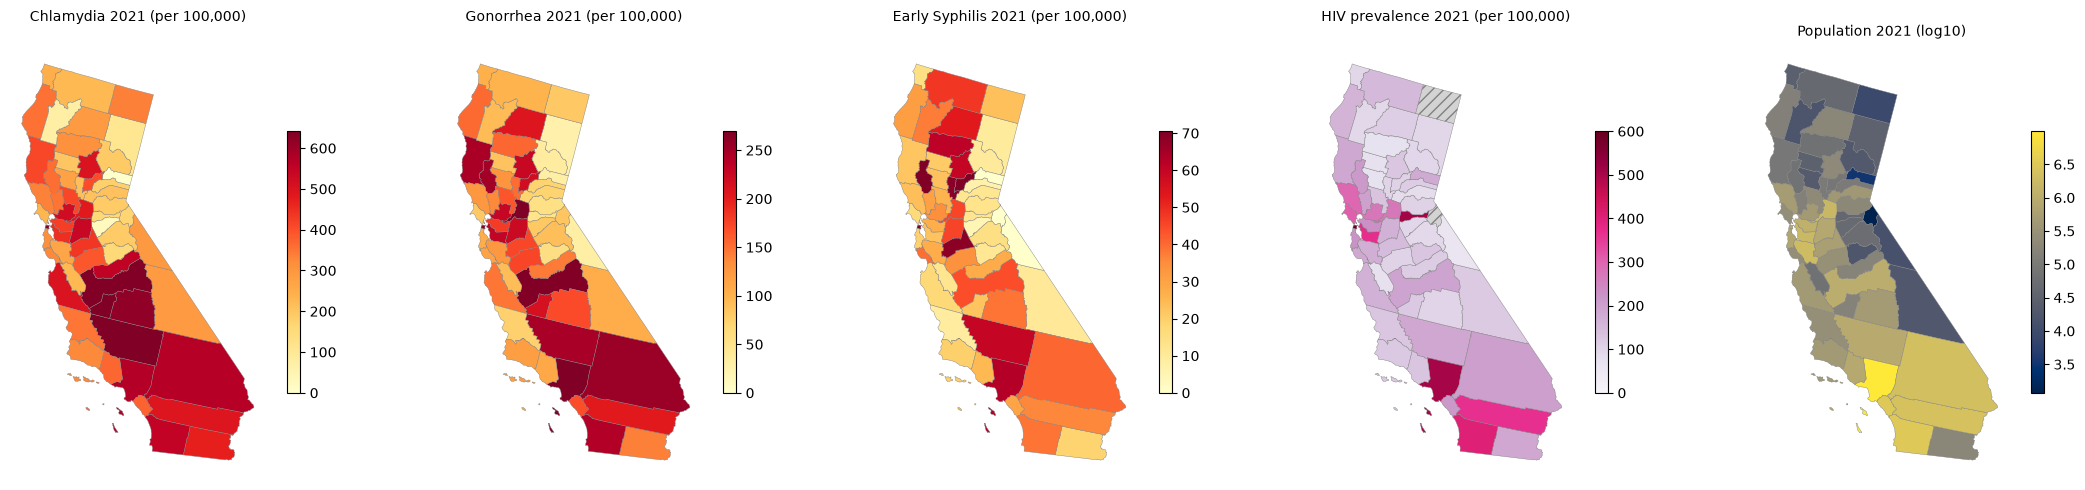

In [5]:
# Choropleth helper. Missing values stay visible as hatched polygons.
def county_map(ax, values, title, cmap="YlOrRd", vmin=None, vmax=None, norm_=None, label=""):
    kw = {"norm": norm_} if norm_ is not None else {"vmin": vmin, "vmax": vmax}
    ca.assign(_v=np.asarray(values, float)).plot(column="_v", ax=ax, cmap=cmap, edgecolor="grey", linewidth=0.3,
                                                legend=True, legend_kwds={"shrink": 0.6, "label": label},
                                                missing_kwds={"color": "lightgrey", "hatch": "///"}, **kw)
    ax.set_title(title, fontsize=10); ax.set_axis_off()

hiv_2021 = chr_[chr_["year"] == 2021].set_index("fips").reindex(FIPS)
# 2021 maps for the three reportable infections, HIV prevalence, and log population.
fig, axes = plt.subplots(1, 5, figsize=(22, 5))
for ax, d_ in zip(axes[:3], DISEASES):
    county_map(ax, RATE[d_][:, -1], f"{d_} 2021 (per 100,000)", vmin=0, vmax=np.nanpercentile(RATE[d_][:, -1], 95))
county_map(axes[3], B * hiv_2021["hiv_cases"] / hiv_2021["census_total_population"], "HIV prevalence 2021 (per 100,000)",
           "PuRd", 0, 600)
county_map(axes[4], np.log10(POP_STD[:, -1]), "Population 2021 (log10)", "cividis")
plt.tight_layout(); plt.show()

**Reading the results.**

- **The panel is complete.** All 58 counties have a total for each disease and year from 2001 to 2021. Small numbers are flagged but not hidden: `*` marks 1 to 11 cases and `#` marks none. For early syphilis, 701 of the 1,218 county-years (58%) have fewer than 12 cases.
- **Populations differ 8,000-fold.** Alpine County has 1,181 people and Los Angeles 9.9 million. Counties also differ 400-fold in area (125 to 52,098 km²).
- **HIV counts are suppressed in four counties:** Alpine and Modoc in every year, Sierra from 2023, and Amador in 2020. For 2020 and 2021, Alpine and Modoc are missing.
- **Two sets of centroids.** The centroids in the CHR file lie a median 12 km (up to 96 km) from the polygon centroids, so they are probably computed differently, possibly population-weighted. The polygon centroids are used throughout.
- **The maps** show the highest chlamydia rates in San Francisco and the southern Central Valley (Kings, Kern, Fresno, Tulare), early syphilis high in San Francisco, the Sacramento Valley and parts of the Central Valley, and HIV highest in San Francisco, Amador, Los Angeles, San Diego and Alameda.

## Exploratory analysis

### Trends and small numbers

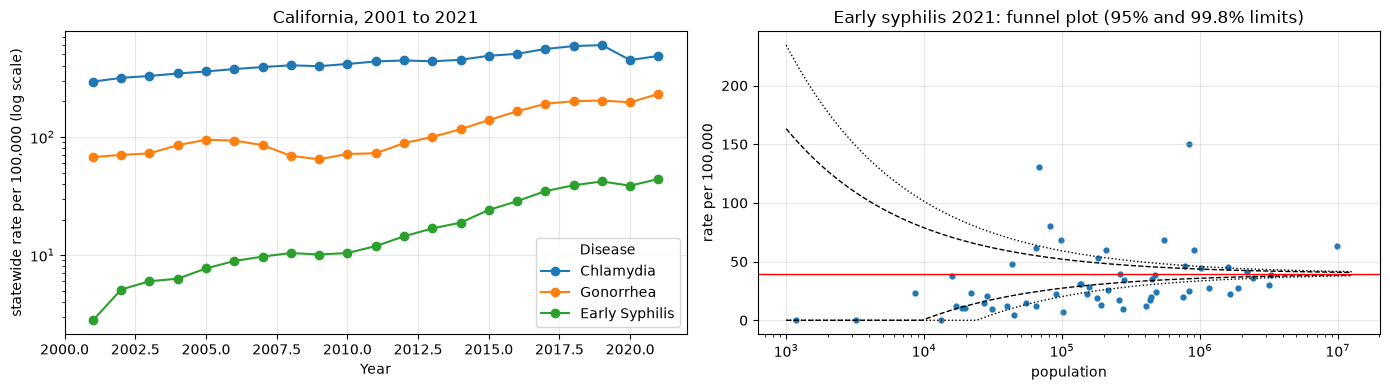

Rate in 2021 / rate in 2001: {'Chlamydia': 1.7, 'Early Syphilis': 15.8, 'Gonorrhea': 3.4}


,Chlamydia,Gonorrhea,Early Syphilis
"counties with 1-11 or 0 cases, 2021",2,7,17
"counties with 0 cases, 2021",1,0,3


In [6]:
# Statewide trend on a log scale, and a funnel showing how far sampling noise alone can move a 2021 rate.
state = raw[(raw["Sex"] == "Total") & (raw["County"] == "California")].pivot(index="Year", columns="Disease", values="Rate")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
state[DISEASES].plot(ax=axes[0], marker="o", logy=True)
axes[0].set_ylabel("statewide rate per 100,000 (log scale)"); axes[0].set_title("California, 2001 to 2021")
d_ = "Early Syphilis"
p = np.nansum(CASES[d_][:, -5:]) / np.nansum(POP_STD[:, -5:])
nn = np.logspace(3, 7.1, 200)
axes[1].scatter(POP_STD[:, -1], RATE[d_][:, -1], s=12)
# Normal limits at 95% and 99.8% around the state rate, drawn against county population.
for z, ls in [(1.96, "--"), (3.09, ":")]:
    axes[1].plot(nn, B * (p + z * np.sqrt(p / nn)), "k", ls=ls, lw=1)
    axes[1].plot(nn, np.clip(B * (p - z * np.sqrt(p / nn)), 0, None), "k", ls=ls, lw=1)
axes[1].axhline(B * p, color="red", lw=1)
axes[1].set_xscale("log"); axes[1].set_xlabel("population"); axes[1].set_ylabel("rate per 100,000")
axes[1].set_title("Early syphilis 2021: funnel plot (95% and 99.8% limits)")
plt.tight_layout(); plt.show()

# Change from 2001 to 2021, and how many counties still report fewer than 12 cases.
growth = state.loc[2021] / state.loc[2001]
print("Rate in 2021 / rate in 2001:", growth.round(1).to_dict())
small = pd.DataFrame({d_: [(CASES[d_][:, -1] < 12).sum(), (CASES[d_][:, -1] == 0).sum()] for d_ in DISEASES},
                     index=["counties with 1-11 or 0 cases, 2021", "counties with 0 cases, 2021"])
display(small)

### Where does information come from?

Three correlations measure how much each kind of borrowing could help, for the 2017 to 2021 period: between a county's rate and the population-weighted mean rate of its five nearest counties (space), between a county's rate in consecutive years (time), and between the rates of two diseases in the same county (across diseases).

In [7]:
# Correlation with the five nearest counties, and of each county with itself across years.
_, NB5 = cKDTree(XY).query(XY, k=6)
def neighbour_corr(r, w):
    nr = np.array([np.average(r[NB5[i, 1:]], weights=w[NB5[i, 1:]]) for i in range(len(r))])
    return np.corrcoef(r, nr)[0, 1], np.corrcoef(np.log1p(r), np.log1p(nr))[0, 1]

rows = {}
for d_ in DISEASES:
    c5, p5 = np.nansum(CASES[d_][:, -5:], 1), np.nansum(POP_STD[:, -5:], 1)
    r5 = B * c5 / p5
    sp, sp_log = neighbour_corr(r5, p5)
    yr = np.mean([np.corrcoef(RATE[d_][:, t], RATE[d_][:, t + 1])[0, 1] for t in range(len(YEARS) - 5, len(YEARS) - 1)])
    rows[d_] = {"space: 5 nearest counties": sp, "space, log rates": sp_log, "time: consecutive years": yr,
                "time: 2011 vs 2021": np.corrcoef(RATE[d_][:, YEARS == 2011][:, 0], RATE[d_][:, -1])[0, 1]}
info = pd.DataFrame(rows).T

# Cross-disease correlation with HIV in 2020-2021, using only counties where HIV is reported.
hiv_cases_2021 = chr_[chr_["year"].isin([2020, 2021])].groupby("fips")["hiv_cases"].mean().reindex(FIPS).to_numpy()
pop2021 = POP_STD[:, -2:].mean(1)
hiv_rate = B * hiv_cases_2021 / pop2021
ok = np.isfinite(hiv_rate)
for d_ in DISEASES:
    info.loc[d_, "across: with HIV (2020-21)"] = np.corrcoef(hiv_rate[ok], (B * CASES[d_][:, -2:].mean(1) / pop2021)[ok])[0, 1]
info.round(2)

,space: 5 nearest counties,"space, log rates",time: consecutive years,time: 2011 vs 2021,across: with HIV (2020-21)
Chlamydia,0.41,0.40,0.92,0.85,0.38
Gonorrhea,0.20,0.42,0.92,0.87,0.68
Early Syphilis,0.02,0.36,0.92,0.60,0.59


**Reading the results.**

- **Early syphilis rose 15.8-fold** between 2001 and 2021, gonorrhea 3.4-fold and chlamydia 1.7-fold. In 2021, 17 counties had fewer than 12 early syphilis cases and 3 had none. Their rates are dominated by chance, as the funnel plot shows.
- **Space carries little information.** A county's rate correlates with the mean of its five nearest counties at 0.41 for chlamydia, 0.20 for gonorrhea and 0.02 for early syphilis. On log rates the correlations are about 0.4 for all three. A metropolitan core and its suburbs often differ more than counties far apart.
- **Time carries a lot.** Rates in consecutive years correlate at 0.92 for all three infections, and even rates ten years apart correlate at 0.85 (chlamydia), 0.87 (gonorrhea) and 0.60 (early syphilis).
- **Other diseases carry a lot for HIV.** HIV prevalence correlates with gonorrhea at 0.68 and with early syphilis at 0.59, against 0.38 with chlamydia.

The kriging results in Sections 4 to 6 follow this ranking: time first, other diseases second, space last.

## Poisson semivariograms with 58 counties

Two estimators of the risk semivariogram are compared, each averaged over the five annual maps 2017 to 2021 to reduce noise:

- **Population-weighted** (Monestiez et al., 2006; `pck_variogram`): each pair is weighted by nᵢnⱼ/(nᵢ+nⱼ) and the Poisson bias B²m* is subtracted.
- **Unweighted, bias-corrected:** the ordinary semivariance of the rates minus the Poisson noise of the pair, ½B²m*(1/nᵢ + 1/nⱼ).

With only 58 counties, the population weights concentrate on a handful of metropolitan pairs, so the weighted estimator mainly describes the Bay Area and Los Angeles. An exponential model with nugget is fitted to the unweighted estimator by weighted least squares (weights: number of pairs).

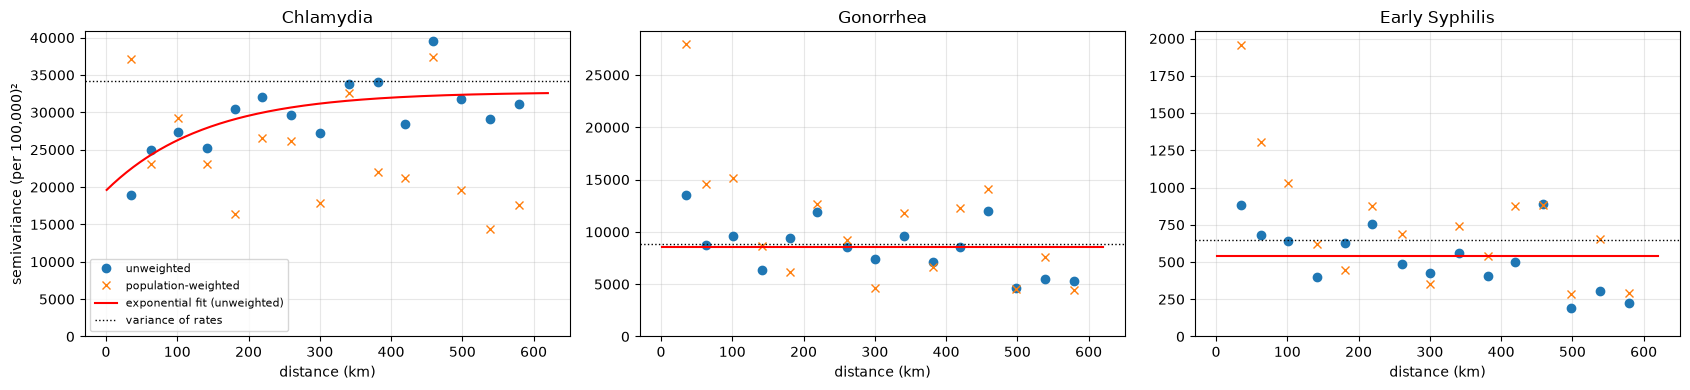

,nugget,partial sill,a (km),practical range (km),nugget share
Chlamydia,19526.75,13211.88,140.55,421.64,0.6
Gonorrhea,8592.57,0.02,5.97,17.91,1.0
Early Syphilis,536.99,0.00,5.29,15.86,1.0


In [8]:
# Centroid distances, binned every 40 km out to 640 km.
D_PAIRS = pdist(XY)
II, JJ = np.triu_indices(len(XY), 1)
EDGES = np.arange(0, 640, 40)

# Semivariance of the rates after the Poisson sampling variance has been removed.
def unweighted_poisson_variogram(cases, pop, xy_idx=None, edges=EDGES):
    idx = np.arange(len(cases)) if xy_idx is None else xy_idx
    D = pdist(XY[idx]); ii, jj = np.triu_indices(len(idx), 1)
    c, n = cases[idx], pop[idx]
    r = B * c / n
    m = np.nansum(c) / np.nansum(n)
    g = 0.5 * (r[ii] - r[jj]) ** 2 - 0.5 * B * B * m * (1 / n[ii] + 1 / n[jj])
    b = np.digitize(D, edges) - 1
    k = range(len(edges) - 1)
    return (np.array([D[b == q].mean() for q in k]), np.array([g[b == q].mean() for q in k]),
            np.array([(b == q).sum() for q in k], dtype=float))

# Exponential fit weighted by the square root of the pair count. The sill starts from the last four bins.
def fit_exp(h, g, n, a0=100.0):
    v = max(np.nanmean(g[-4:]), 1e-6 * np.nanmax(np.abs(g)) + 1e-9)
    f = lambda p: np.sqrt(n) * (p[0] + p[1] * (1 - np.exp(-h / p[2])) - g)
    r = least_squares(f, [0.4 * v, 0.6 * v, a0], bounds=([0, 1e-9, 5], [np.inf, np.inf, 2000]))
    return tuple(float(x) for x in r.x)                       # nugget, partial sill, a (km)

def exp_gamma(h, p):
    return p[0] + p[1] * (1 - np.exp(-np.asarray(h) / p[2]))

# Average 2017-2021, and compare the unweighted bins with the population-weighted estimator.
VG, VPAR = {}, {}
last5 = [list(YEARS).index(y) for y in range(2017, 2022)]
for d_ in DISEASES:
    un = [unweighted_poisson_variogram(CASES[d_][:, t], POP_STD[:, t]) for t in last5]
    pw = [mpk.pck_variogram(XY, CASES[d_][:, t], POP_STD[:, t], pop_rate=B, maxd=600, nbins=15) for t in last5]
    VG[d_] = {"unweighted": (un[0][0], np.mean([u[1] for u in un], 0), un[0][2]),
              "population-weighted": (pw[0][0], np.mean([q[1] for q in pw], 0), pw[0][2])}
    VPAR[d_] = fit_exp(*VG[d_]["unweighted"])

# Binned estimates, the fitted exponential, and the plain variance of the rates as a reference line.
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
hh = np.linspace(1, 620, 200)
for ax, d_ in zip(axes, DISEASES):
    for est, mk in [("unweighted", "o"), ("population-weighted", "x")]:
        h, g, n = VG[d_][est]
        ax.plot(h, g, mk, label=est)
    ax.plot(hh, exp_gamma(hh, VPAR[d_]), "r-", label="exponential fit (unweighted)")
    ax.axhline(np.nanvar(RATE[d_][:, last5]), color="k", ls=":", lw=1, label="variance of rates")
    ax.set_xlabel("distance (km)"); ax.set_title(d_); ax.set_ylim(0, None)
axes[0].set_ylabel("semivariance (per 100,000)²"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame({d_: {"nugget": VPAR[d_][0], "partial sill": VPAR[d_][1], "a (km)": VPAR[d_][2],
                   "practical range (km)": 3 * VPAR[d_][2],
                   "nugget share": VPAR[d_][0] / (VPAR[d_][0] + VPAR[d_][1])} for d_ in DISEASES}).T.round(2)

**Reading the results.**

- **Only chlamydia has spatial structure.** Its unweighted semivariogram rises from about 19,500 at short distances to a sill near 33,000, with a practical range of about 420 km. The nugget is 60% of the sill.
- **Gonorrhea and early syphilis are pure nugget.** Their semivariograms are flat, and the fit puts all the variance in the nugget. Neighbouring counties are no more alike than distant ones.
- **The population-weighted estimator is unstable here.** Its first lag is far above the sill for all three infections. The few pairs of large neighbouring counties (San Francisco and its neighbours, Los Angeles and Orange) dominate it, and those pairs differ strongly, so the estimator mainly describes the urban core against its suburbs.

## Poisson kriging in space: centroid, area-to-area and area-to-point

### Point support

Area-to-area kriging needs each county as a set of points with weights. Population points (for example census blocks) are not in the data folder, so each county is filled with a regular grid of about 150 points and its population is spread evenly over them. This captures size and shape, but not where people live within a county, a limitation discussed at the end. `PointSupport` stores the points by county.

In [9]:
# Support points inside each county. Spacing is at least 1.5 km, and wider in large counties so a county gets about 150 points.
rows = []
for _, row in ca.iterrows():
    geom = row.geometry
    sp = max(1500.0, np.sqrt(geom.area / 150))
    x0, y0, x1, y1 = geom.bounds
    gx, gy = np.meshgrid(np.arange(x0 + sp / 2, x1, sp), np.arange(y0 + sp / 2, y1, sp))
    pts = gpd.GeoSeries(gpd.points_from_xy(gx.ravel(), gy.ravel()), crs=ca.crs)
    pts = pts[pts.within(geom)]
    if len(pts) == 0:
        pts = gpd.GeoSeries([geom.representative_point()], crs=ca.crs)
    rows.append(pd.DataFrame({"fips": row["fips"], "x": pts.x.to_numpy() / 1000, "y": pts.y.to_numpy() / 1000}))
SUPPORT = pd.concat(rows, ignore_index=True)
print(f"Support points: {len(SUPPORT):,}; per county {SUPPORT.groupby('fips').size().min()} to {SUPPORT.groupby('fips').size().max()}")

# Split the county population equally across its support points.
def point_support(pop):
    w = SUPPORT["fips"].map(pd.Series(pop, index=FIPS)) / SUPPORT["fips"].map(SUPPORT.groupby("fips").size())
    return PointSupport(SUPPORT[["x", "y"]].to_numpy(), w.to_numpy(), SUPPORT["fips"].to_numpy())

Support points: 8,653; per county 58 to 155


### Leave-one-out comparison

Each county's 2021 rate is predicted from its 8 nearest counties, without its own data, by centroid Poisson kriging (`PoissonKriging.predict_id`) and by area-to-area Poisson kriging (`AreaPoissonKriging.predict_area`). The baselines are the statewide rate and the population-weighted mean of the same 8 neighbours. Because the observed rates of small counties are themselves noisy, errors are weighted by population, as in Goovaerts (2006), and also shown unweighted.

In [10]:
# Turn the fitted nugget, partial sill, and range into an exponential variogram.
def make_variogram(params, xy, z):
    return Variogram(xy, z, model="exponential").set_params(*params)

# Leave-one-out at one year: the statewide rate, eight neighbours, centroid kriging, and area-to-area kriging.
def spatial_loo(d_, t=-1, k=K_SPACE):
    cases, pop = CASES[d_][:, t], POP_STD[:, t]
    rate = B * cases / pop
    vg = make_variogram(VPAR[d_], XY, rate)
    pk = PoissonKriging(vg, rate_base=B, use_gpu=False).fit(XY, rate, pop, ids=FIPS)
    apk = AreaPoissonKriging(vg, rate_base=B).fit(point_support(pop), pd.Series(rate, index=FIPS))
    out = {"statewide rate": np.full(len(rate), B * cases.sum() / pop.sum())}
    _, nb = cKDTree(XY).query(XY, k=k + 1)
    out["mean of 8 neighbours"] = np.array([np.average(rate[nb[i, 1:]], weights=pop[nb[i, 1:]]) for i in range(len(rate))])
    out["centroid PK"] = np.array([pk.predict_id(f, number_of_neighbors=k)["zhat"] for f in FIPS])
    out["ATA PK"] = np.array([apk.predict_area(f, number_of_neighbors=k)["zhat"] for f in FIPS])
    return rate, pop, out, pk, apk

# 2021 scores. Population-weighted mean squared error is reported against the statewide rate.
LOO = {}
rows = []
for d_ in DISEASES:
    rate, pop, out, _, _ = spatial_loo(d_)
    LOO[d_] = out
    for m, p in out.items():
        e = p - rate
        rows.append({"disease": d_, "method": m, "pop-weighted MSE": np.average(e ** 2, weights=pop),
                     "MSE": np.mean(e ** 2), "pop-weighted ME": np.average(e, weights=pop),
                     "Spearman": stats.spearmanr(p, rate)[0]})
loo_tab = pd.DataFrame(rows).set_index(["disease", "method"])
loo_tab["pop-weighted MSE vs statewide (%)"] = 100 * loo_tab["pop-weighted MSE"] / loo_tab.groupby(level=0)["pop-weighted MSE"].transform("first")
loo_tab.round(2)

pop-weighted MSE       MSE  pop-weighted ME  Spearman  pop-weighted MSE vs statewide (%)
disease        method                                                                                                        
Chlamydia      statewide rate                14728.73  45071.43            -0.00       NaN                             100.00
               mean of 8 neighbours          15045.53  28253.65            -0.22      0.43                             102.15
               centroid PK                   18017.57  19330.38           -46.73      0.59                             122.33
               ATA PK                        17033.30  19462.68           -34.84      0.59                             115.65
Gonorrhea      statewide rate                 8585.50  15219.15            -0.00       NaN                             100.00
               mean of 8 neighbours          12534.30  13255.56            -5.27      0.10                             145.99
               centroid PK                   12529.84  13251.49            -5.32      0.10                             145.94
               ATA PK                        12555.85  13269.71            -5.40      0.10                             146.24
Early Syphilis statewide rate                  522.62    890.71            -0.00       NaN                             100.00
               mean of 8 neighbours            792.46   1022.41            -0.81      0.06                             151.63
               centroid PK                     792.45   1022.40            -0.81      0.06                             151.63
               ATA PK                          796.33   1024.64            -1.11      0.03                             152.37

**Reading the results.**

- **Kriging does not beat the statewide rate in population-weighted MSE.** For chlamydia, centroid PK and ATA have 22% and 16% higher population-weighted MSE than the statewide rate. For gonorrhea and early syphilis, whose models are pure nugget, kriging reduces to the population-weighted mean of the 8 neighbours and is 46% to 52% worse. The large counties dominate this score, and their rates are close to the statewide rate, which they largely determine.
- **Unweighted, kriging helps chlamydia.** Its unweighted MSE falls from 45,071 (statewide rate) to 19,330 (centroid PK) and 19,463 (ATA), and the rank correlation with the observed rate is 0.59.
- **ATA and centroid PK give almost the same answers.** ATA is slightly better in population-weighted MSE for chlamydia (17,033 against 18,018), but the difference is small next to the differences between counties.

With 58 counties, a weak spatial structure and very unequal populations, spatial Poisson kriging is mainly a smoother for small counties, not a predictor of unobserved ones.

### Filtered county rates and the area-to-point surface

For the maps, each county keeps its own rate in the system, with its Poisson error term on the diagonal (`exclude_self=False`, added to the package for this capstone). The result is the noise-filtered county risk of Goovaerts (2006): close to the observed rate in large counties, pulled towards the neighbours in small ones. The area-to-point surface is computed on a 5 km grid, each node using the kriging system of the county that contains it. The coherence check compares the population-weighted average of each county's point estimates with its area-to-area estimate.

In [11]:
# Chlamydia in 2021. Keeping each county in its own system produces a filtered rate rather than a blank-county prediction.
d_ = "Chlamydia"
rate, pop, _, pk_c, apk_c = spatial_loo(d_)
t0 = time.time()
ata = pd.DataFrame([apk_c.predict_area(f, number_of_neighbors=K_SPACE, exclude_self=False) for f in FIPS]).set_index("id")
cent = pk_c.predict(XY, number_of_neighbors=K_SPACE)[0]

# Coherence check: the population-weighted mean of the point predictions should match the area prediction.
coh = []
for f in FIPS:
    pp = apk_c.predict_points(f, number_of_neighbors=K_SPACE, exclude_self=False)
    coh.append(np.average(pp["zhat"], weights=pp["population"]))
print(f"ATA and coherence check: {time.time() - t0:.1f} s")
print(f"Coherence: max |population-weighted ATP mean - ATA| = {np.nanmax(np.abs(np.array(coh) - ata['zhat'].to_numpy())):.2e}")

# 5 km grid for the ATP surface
gx, gy = np.meshgrid(np.arange(*ca.total_bounds[[0, 2]], 5000), np.arange(*ca.total_bounds[[1, 3]], 5000))
grid = gpd.GeoDataFrame(geometry=gpd.points_from_xy(gx.ravel(), gy.ravel()), crs=ca.crs)
grid = gpd.sjoin(grid, ca[["fips", "geometry"]], predicate="within").drop(columns="index_right").reset_index(drop=True)
t0 = time.time()
atp = []
for f, g in grid.groupby("fips"):
    tg = np.column_stack([g.geometry.x, g.geometry.y]) / 1000
    pp = apk_c.predict_points(f, number_of_neighbors=K_SPACE, exclude_self=False, targets=tg)
    atp.append(pd.DataFrame({"x": tg[:, 0], "y": tg[:, 1], "zhat": pp["zhat"].to_numpy(), "sig": pp["sig"].to_numpy(), "fips": f}))
ATP = pd.concat(atp, ignore_index=True)
print(f"ATP surface: {len(ATP):,} nodes in {time.time() - t0:.1f} s")

# Smallest and largest counties, where filtering moves the rate the most.
small = pd.DataFrame({"county": ca["name"], "population": pop.astype(int), "observed": rate, "centroid PK": cent,
                      "ATA (filtered)": ata["zhat"].to_numpy(), "ATA SD": ata["sig"].to_numpy()})
display(small.sort_values("population").head(10).round(1))
display(small.sort_values("population").tail(5).round(1))

ATA and coherence check: 1.6 s
Coherence: max |population-weighted ATP mean - ATA| = 3.13e-12


ATP surface: 16,386 nodes in 1.8 s


,county,population,observed,centroid PK,ATA (filtered),ATA SD
1,Alpine,1181,169.3,188.4,210.5,49.5
45,Sierra,3213,0.0,129.2,135.3,34.4
24,Modoc,8579,338.0,300.5,268.7,41.6
25,Mono,13258,294.2,307.1,352.4,45.7
52,Trinity,16011,74.9,134.9,211.5,29.4
21,Mariposa,17016,158.7,251.5,308.5,30.6
13,Inyo,18879,291.3,352.1,420.2,39.6
31,Plumas,19720,192.7,198.6,204.3,28.4
5,Colusa,21867,274.4,283.3,280.3,26.6
7,Del Norte,27365,248.5,252.9,258.2,30.4


,county,population,observed,centroid PK,ATA (filtered),ATA SD
35,San Bernardino,2186572,570.8,570.5,571.6,NaN
32,Riverside,2431238,494.4,494.4,494.3,NaN
29,Orange,3163851,374.3,374.6,374.4,NaN
36,San Diego,3284368,550.8,550.6,551.1,NaN
18,Los Angeles,9905214,572.3,572.2,573.8,NaN


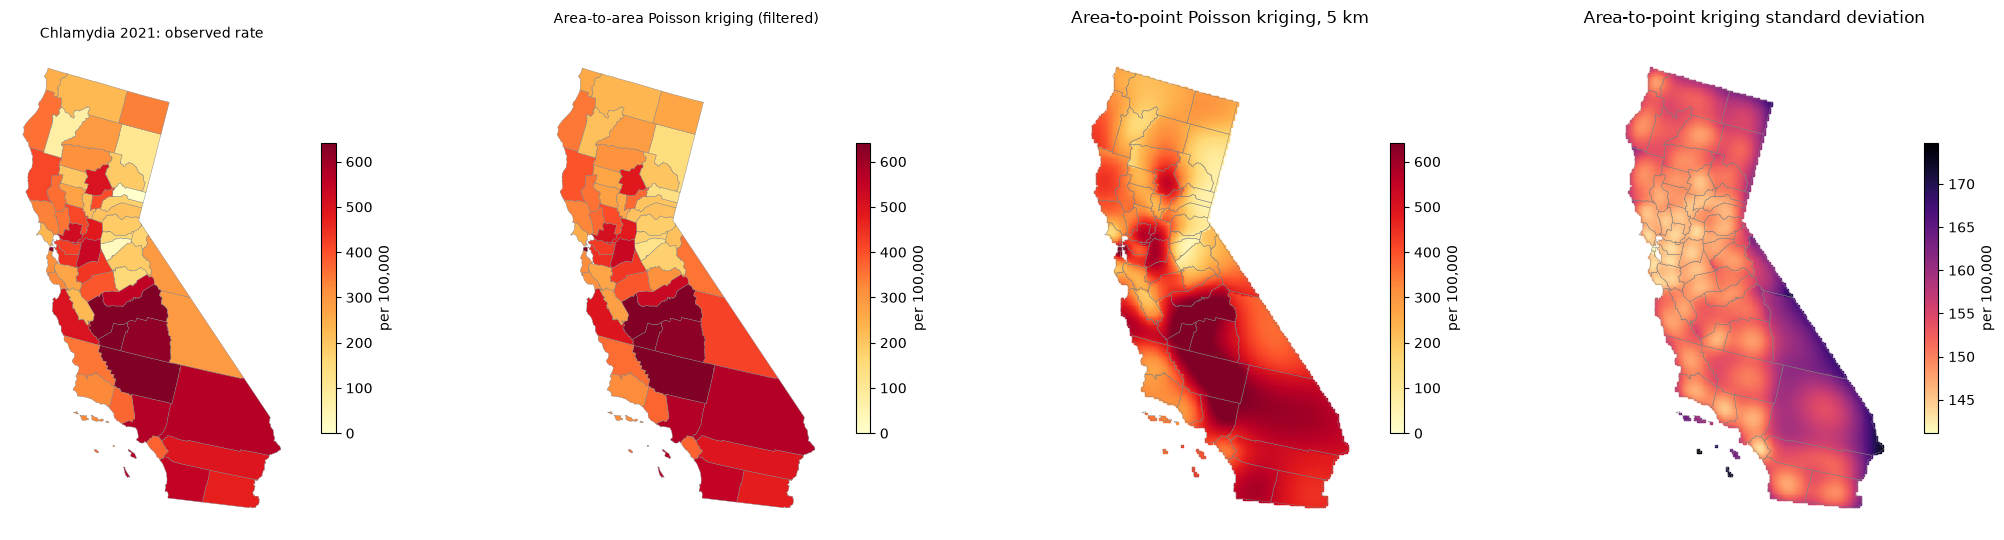

In [12]:
# Rate maps stop at the 95th percentile so a few high counties do not set the colour scale. The last panel is the kriging standard deviation.
vmax = np.percentile(rate, 95)
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
county_map(axes[0], rate, f"{d_} 2021: observed rate", vmin=0, vmax=vmax, label="per 100,000")
county_map(axes[1], ata["zhat"], "Area-to-area Poisson kriging (filtered)", vmin=0, vmax=vmax, label="per 100,000")
sc = axes[2].scatter(ATP["x"] * 1000, ATP["y"] * 1000, c=ATP["zhat"], s=2, marker="s", cmap="YlOrRd", vmin=0, vmax=vmax)
ca.boundary.plot(ax=axes[2], color="grey", linewidth=0.3); plt.colorbar(sc, ax=axes[2], shrink=0.6, label="per 100,000")
axes[2].set_title("Area-to-point Poisson kriging, 5 km"); axes[2].set_axis_off()
sc = axes[3].scatter(ATP["x"] * 1000, ATP["y"] * 1000, c=ATP["sig"], s=2, marker="s", cmap="magma_r")
ca.boundary.plot(ax=axes[3], color="grey", linewidth=0.3); plt.colorbar(sc, ax=axes[3], shrink=0.6, label="per 100,000")
axes[3].set_title("Area-to-point kriging standard deviation"); axes[3].set_axis_off()
plt.tight_layout(); plt.show()

**Reading the results.**

- **Coherence holds.** The population-weighted mean of the area-to-point estimates reproduces the area-to-area estimate in every county, to 4e-12.
- **Large counties keep their own rate**, for example Los Angeles 572 per 100,000 observed and 574 filtered.
- **Small counties are pulled towards their neighbours, ATA more strongly than centroid PK.** Sierra (3,213 people, no cases in 2021) gets 129 from centroid PK and 135 from ATA. Inyo goes from 291 to 352 and 420. ATA shrinks more because it treats the areal nugget (60% of the sill) as variation between points inside a county, which averages out over the county, so the county's own block variance is smaller than its observed variance. A point-support (deconvoluted) variogram would correct this (Goovaerts, 2008).
- **ATA variances are undefined for the largest counties** (NaN for San Bernardino, Riverside, Orange, San Diego and Los Angeles). The same mismatch makes their block covariance smaller than the variance that kriging removes.
- **The area-to-point surface** shows the Central Valley maximum as a smooth ridge instead of county blocks. The standard deviation is lowest near county centres and highest in the eastern desert, where support points lie far from neighbouring counties.

## Poisson cokriging of HIV with gonorrhea and early syphilis

HIV counts for 2020 and 2021 are averaged and paired with the gonorrhea and early syphilis counts of the same years, using the same population for all three, as the cross-semivariogram requires. Two counties, Alpine and Modoc, have suppressed HIV counts in both years and are the real prediction targets.

The direct and cross semivariograms use the unweighted, bias-corrected estimators of Section 3; the cross bias is the mean joint risk r_lk = ρ√(R_l R_k) (`shared_risk`), with ρ the correlation of the rates. `fit_lmc` fits a linear model of coregionalization with a nugget and one exponential structure, and `poisson_cokrige` solves the global system (all counties). The estimators are compared by leave-one-out smoothing, and in a masking experiment where HIV is hidden in 30% of counties at random, which mimics suppression.

In [13]:
# HIV in 2020-2021 with gonorrhea and early syphilis as auxiliaries. Suppressed counties are held out of the HIV data.
HIV_VARS = ["HIV", "Gonorrhea", "Early Syphilis"]
pop_h = POP_STD[:, -2:].mean(1)
Yh = [hiv_cases_2021, CASES["Gonorrhea"][:, -2:].mean(1), CASES["Early Syphilis"][:, -2:].mean(1)]
Rh = [B * y / pop_h for y in Yh]
OBS = np.flatnonzero(np.isfinite(Yh[0]))
MISSING = np.flatnonzero(~np.isfinite(Yh[0]))
RHO_H = np.corrcoef([r[OBS] for r in Rh])
print("Counties with HIV observed:", len(OBS), " suppressed:", ca.loc[MISSING, "name"].tolist())
print("Correlation of rates (HIV, gonorrhea, early syphilis):\n", RHO_H.round(2))

# Cross-semivariogram in 80 km bins, with the shared Poisson sampling term removed.
def cross_variogram(idx, a, b, edges=np.arange(0, 640, 80)):
    D = pdist(XY[idx]); ii, jj = np.triu_indices(len(idx), 1)
    n = pop_h[idx]; ra, rb = Rh[a][idx], Rh[b][idx]
    rlk = mpk.shared_risk(ra, rb, RHO_H[a, b])
    g = 0.5 * (ra[ii] - ra[jj]) * (rb[ii] - rb[jj]) - 0.5 * B * rlk.mean() * (1 / n[ii] + 1 / n[jj])
    bins = np.digitize(D, edges) - 1; k = range(len(edges) - 1)
    return (np.array([D[bins == q].mean() for q in k]), np.array([g[bins == q].mean() for q in k]),
            np.array([(bins == q).sum() for q in k], dtype=float)), float(rlk.mean())

# One shared exponential range for the direct and cross variograms.
def fit_hiv_lmc(idx_target, P):
    # direct variogram of HIV on counties where it is observed; auxiliaries on all counties
    dv = [unweighted_poisson_variogram(Yh[0], pop_h, idx_target, edges=np.arange(0, 640, 80))]
    dv += [unweighted_poisson_variogram(Yh[l], pop_h, None, edges=np.arange(0, 640, 80)) for l in range(1, P)]
    pairs = [(a, b) for a in range(P) for b in range(a + 1, P)]
    cv, shared = [], {}
    for a, b in pairs:
        idx = idx_target if 0 in (a, b) else np.arange(len(pop_h))
        v, s = cross_variogram(idx, a, b); cv.append(v); shared[(a, b)] = s
    lmc = mpk.fit_lmc(dv, cv, pairs, P, 100.0, model="Exp", fit_range=True, nugget=True, range_grid=np.arange(20, 410, 10))
    return lmc, shared

# Primary variable first, restricted to counties where it is observed. Auxiliaries use all 58 counties.
def hiv_datasets(idx_target, P):
    ds = [dict(x=XY[idx_target, 0], y=XY[idx_target, 1], cases=Yh[0][idx_target], pop=pop_h[idx_target])]
    ds += [dict(x=XY[:, 0], y=XY[:, 1], cases=Yh[l], pop=pop_h) for l in range(1, P)]
    return ds

# Fit HIV alone, HIV with gonorrhea, and HIV with both infections.
LMC_H = {}
for P in (1, 2, 3):
    LMC_H[P] = fit_hiv_lmc(OBS, P)
lmc3 = LMC_H[3][0]
display(pd.concat({"nugget B0": pd.DataFrame(lmc3.B0, HIV_VARS, HIV_VARS),
                   "structured sill B": pd.DataFrame(lmc3.B, HIV_VARS, HIV_VARS)}).round(0))
d0 = np.sqrt(np.diag(lmc3.B0)); tot = np.sqrt([lmc3.sill(l) for l in range(3)])
print("Range parameter:", lmc3.range, "km;  nugget share of HIV sill:", round(lmc3.B0[0, 0] / lmc3.sill(0), 2))
print("Nugget correlations:", {f"{HIV_VARS[a]}-{HIV_VARS[b]}": round(lmc3.B0[a, b] / (d0[a] * d0[b]), 2) for a, b in [(0, 1), (0, 2), (1, 2)]})

Counties with HIV observed: 56  suppressed: ['Alpine', 'Modoc']
Correlation of rates (HIV, gonorrhea, early syphilis):
 [[1.   0.68 0.59]
 [0.68 1.   0.82]
 [0.59 0.82 1.  ]]


HIV  Gonorrhea  Early Syphilis
nugget B0         HIV             52459.0    14143.0          3477.0
                  Gonorrhea       14143.0     8158.0          2179.0
                  Early Syphilis   3477.0     2179.0           717.0
structured sill B HIV              2263.0    -2267.0            68.0
                  Gonorrhea       -2267.0     2301.0          -154.0
                  Early Syphilis     68.0     -154.0           259.0

Range parameter: 400.0 km;  nugget share of HIV sill: 0.96
Nugget correlations: {'HIV-Gonorrhea': np.float64(0.68), 'HIV-Early Syphilis': np.float64(0.57), 'Gonorrhea-Early Syphilis': np.float64(0.9)}


In [14]:
# Weighted error, rank correlation, and coverage of a normal 90% interval (1.645 standard deviations).
def pck_scores(pred, var, obs, pop):
    e = pred - obs; sd = np.sqrt(np.clip(var, 1e-9, None))
    return {"pop-weighted MSE": np.average(e ** 2, weights=pop), "MSE": np.mean(e ** 2),
            "Spearman": stats.spearmanr(pred, obs)[0] if np.ptp(pred) > 1e-6 * max(np.abs(pred).max(), 1) else np.nan,
            "z SD": np.std(e / sd),
            "cover 90%": np.mean(np.abs(e) <= 1.645 * sd)}

# Leave-one-out smoothing on the counties where HIV is observed.
names = {1: "PK (HIV only)", 2: "PCK + gonorrhea", 3: "PCK + gonorrhea + early syphilis"}
SM_H, rows = {}, {}
for P in (1, 2, 3):
    lmc, shared = LMC_H[P]
    SM_H[P] = mpk.poisson_cokrige(hiv_datasets(OBS, P), 0, lmc, pop_rate=B, shared_mean=shared, smooth=True)
    rows[names[P]] = pck_scores(SM_H[P]["rate_pred"], SM_H[P]["rate_var"], SM_H[P]["observed"], pop_h[OBS])
print("Leave-one-out smoothing of HIV (2020-2021), 56 counties")
display(pd.DataFrame(rows).T.round(2))

# Masking experiment: hide HIV in 30% of the observed counties
rng = np.random.default_rng(SEED)
mrows = []
t0 = time.time()
for rep in range(N_MASK):
    hidden = np.sort(rng.choice(OBS, int(round(0.3 * len(OBS))), replace=False))
    keep = np.setdiff1d(OBS, hidden)
    for P in (1, 2, 3):
        lmc, shared = fit_hiv_lmc(keep, P)
        r = mpk.poisson_cokrige(hiv_datasets(keep, P), 0, lmc, pop_rate=B, shared_mean=shared, coords_pred=XY[hidden])
        mrows.append({"rep": rep, "estimator": names[P], **pck_scores(r["pred"], r["var"], Rh[0][hidden], pop_h[hidden])})
MASK = pd.DataFrame(mrows)
print(f"Masking experiment ({N_MASK} replicates, {len(hidden)} counties hidden each): {time.time() - t0:.0f} s")
# Median skill over the 50 replicates. HIV-only kriging is the baseline at 100%.
mask_tab = MASK.groupby("estimator")[["pop-weighted MSE", "MSE", "Spearman", "z SD", "cover 90%"]].median().reindex(list(names.values()))
mask_tab["pop-weighted MSE vs PK (%)"] = 100 * mask_tab["pop-weighted MSE"] / mask_tab.iloc[0]["pop-weighted MSE"]
print("Medians over replicates:")
mask_tab.round(2)

Leave-one-out smoothing of HIV (2020-2021), 56 counties


,pop-weighted MSE,MSE,Spearman,z SD,cover 90%
PK (HIV only),66558.71,39989.29,-1.00,0.87,0.98
PCK + gonorrhea,18336.64,18492.04,0.47,0.75,0.96
PCK + gonorrhea + early syphilis,17890.45,19157.24,0.45,0.77,0.96


Masking experiment (50 replicates, 17 counties hidden each): 2 s
Medians over replicates:


,pop-weighted MSE,MSE,Spearman,z SD,cover 90%,pop-weighted MSE vs PK (%)
estimator,,,,,,
PK (HIV only),33655.35,14801.34,0.57,0.49,1.00,100.00
PCK + gonorrhea,14611.96,23348.88,0.49,1.04,0.94,43.42
PCK + gonorrhea + early syphilis,13847.71,24333.19,0.37,1.05,0.94,41.15


HIV prevalence per 100,000 (estimate ± kriging SD) for the suppressed counties:


,PK (HIV only),PCK + gonorrhea,PCK + gonorrhea + early syphilis,population,gonorrhea rate,early syphilis rate
name,,,,,,
Alpine,191 ± 231,172 ± 217,166 ± 216,1191,42.0,0.0
Modoc,191 ± 231,150 ± 200,143 ± 198,8641,98.0,12.0


Implied number of people living with HIV (PCK + both): {'Alpine': np.float64(2.0), 'Modoc': np.float64(12.4)}


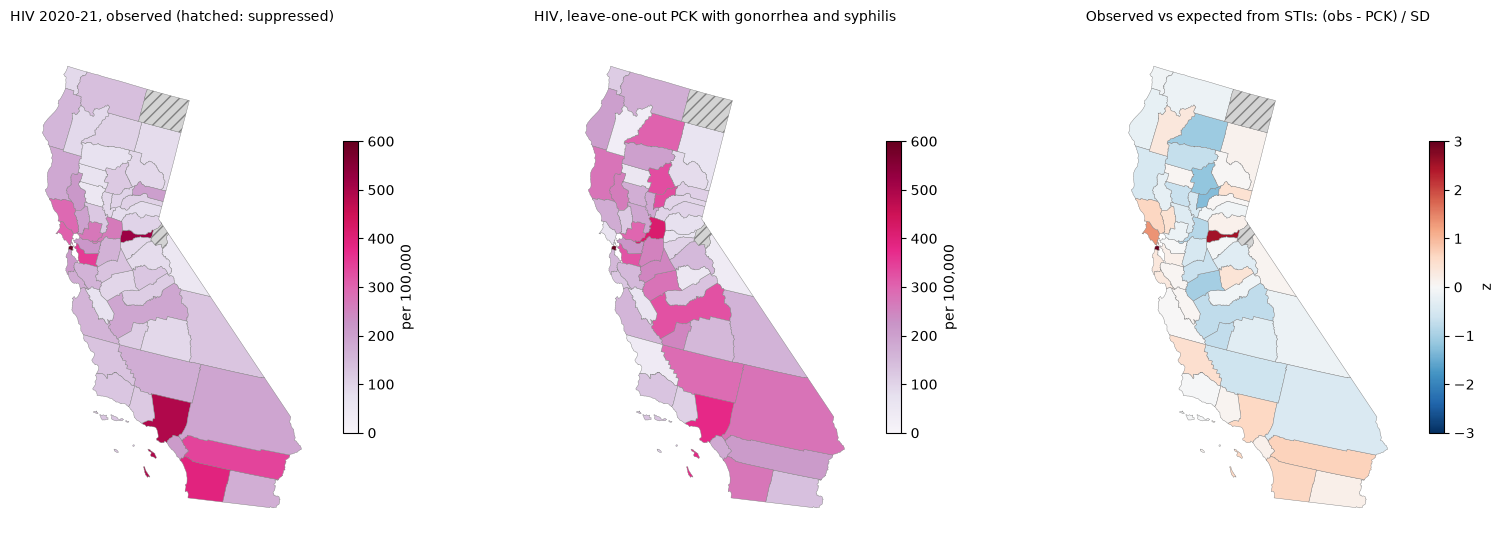

In [15]:
# Prediction for the counties with suppressed HIV counts, from all observed counties
pred_supp, pred_num = {}, {}
for P in (1, 2, 3):
    lmc, shared = LMC_H[P]
    r = mpk.poisson_cokrige(hiv_datasets(OBS, P), 0, lmc, pop_rate=B, shared_mean=shared, coords_pred=XY[MISSING])
    pred_num[P] = r["pred"]
    pred_supp[names[P]] = [f"{z:.0f} ± {np.sqrt(max(v, 0)):.0f}" for z, v in zip(r["pred"], r["var"])]
supp_tab = pd.DataFrame(pred_supp, index=ca.loc[MISSING, "name"])
supp_tab["population"] = pop_h[MISSING].astype(int)
supp_tab["gonorrhea rate"] = Rh[1][MISSING].round(0)
supp_tab["early syphilis rate"] = Rh[2][MISSING].round(0)
print("HIV prevalence per 100,000 (estimate ± kriging SD) for the suppressed counties:")
display(supp_tab)
print("Implied number of people living with HIV (PCK + both):",
      {ca.loc[i, "name"]: round(z * pop_h[i] / B, 1) for i, z in zip(MISSING, pred_num[3])})

# Observed HIV, the leave-one-out cokriging map, and where each county sits relative to the prediction from the other infections.
hiv_full = np.full(len(FIPS), np.nan); hiv_full[OBS] = SM_H[3]["rate_pred"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
obs_map = np.full(len(FIPS), np.nan); obs_map[OBS] = Rh[0][OBS]
county_map(axes[0], obs_map, "HIV 2020-21, observed (hatched: suppressed)", "PuRd", 0, 600, label="per 100,000")
county_map(axes[1], hiv_full, "HIV, leave-one-out PCK with gonorrhea and syphilis", "PuRd", 0, 600, label="per 100,000")
z = np.full(len(FIPS), np.nan); z[OBS] = -SM_H[3]["zscore"]
county_map(axes[2], z, "Observed vs expected from STIs: (obs - PCK) / SD", "RdBu_r", norm_=TwoSlopeNorm(0, -3, 3), label="z")
plt.tight_layout(); plt.show()

**Reading the results.**

- **The model is almost all nugget.** The nugget is 96% of the HIV sill, and the structured part of the LMC is poorly determined: it even has a negative HIV-gonorrhea term. What matters is the nugget correlation of HIV with gonorrhea (0.68) and with early syphilis (0.57). These terms let a county's own STI counts inform its HIV risk.
- **Leave-one-out smoothing.** HIV-only Poisson kriging predicts the same value everywhere, because the HIV semivariogram has no spatial structure; its population-weighted MSE is 66,559. Cokriging with gonorrhea cuts it to 18,337 (−72%), and adding early syphilis to 17,890 (−73%).
- **Masking experiment.** With HIV hidden in 17 counties at random, cokriging lowers the median population-weighted MSE to 43% (with gonorrhea) and 41% (with both) of HIV-only PK. The unweighted MSE rises, from 14,801 to 23,349 and 24,333: the STIs improve the large counties a lot but mislead in some small ones. HIV-only PK has a z-score SD of 0.49, so its intervals are far too wide, while cokriging is close to 1 (1.04) with 94% coverage of the 90% intervals.
- **Suppressed counties.** For Alpine and Modoc, cokriging with both STIs gives 166 ± 216 and 143 ± 198 per 100,000, or about 2 and 12 people living with HIV. The intervals are wide, but the estimates are consistent with counts small enough to be suppressed.
- **Where HIV departs from the STIs.** San Francisco (z = 3.4) and Amador (2.5) have far more HIV than their STI rates predict. Yuba, Butte, Shasta, Merced and Sacramento have less (z about −0.9 to −1.3), where early syphilis rose most steeply between 2005 and 2021 (Section 6).

## Space-time Poisson kriging, 2001 to 2021

`STPoissonKriging` kriges county-year rates in a joint space-time covariance, with each neighbour's Poisson term on the diagonal. Its variogram comes from `empirical_st_variogram`, which bins pairs by spatial lag and time lag.

> **Package change.** In the original estimator, pairs of the *same* county in different years fall into the first spatial bin together with pairs of different, nearby counties. With strong county persistence, this hides the temporal correlation that matters most. The option `zero_distance_bin=True`, added for this capstone, keeps same-county pairs in their own cell at distance 0.

Three space-time models are fitted with `fit_st_variogram`: separable, product-sum and sum-metric. They are compared with a metric model fitted to the original binning, and with three simple predictors: the county's rate in the previous year, the mean of the previous and next year, and spatial-only Poisson kriging of each year.

In [16]:
# One row per county-year, the layout the space-time kriging class expects.
def st_long(d_):
    long = pd.DataFrame({"fips": np.repeat(FIPS, len(YEARS)), "year": np.tile(YEARS, len(FIPS)),
                         "rate": RATE[d_].ravel(), "pop": POP_STD.ravel(),
                         "x": np.repeat(XY[:, 0], len(YEARS)), "y": np.repeat(XY[:, 1], len(YEARS))})
    return long

# Separable, product-sum, and sum-metric starting models. Ranges are in kilometres and years, with a joint anisotropy of 30 km per year.
def st_models(emp):
    v = float(np.average(emp["gamma"], weights=emp["np"]))
    return {
        "separable": vgm_st("separable", space=vgm(0.6, "Exp", 150, 0.4), time=vgm(0.6, "Exp", 10, 0.05), sill=v),
        "product-sum": vgm_st("productSum", space=vgm(0.5 * v, "Exp", 150, 0.3 * v), time=vgm(0.5 * v, "Exp", 10, 0.05 * v), k=1 / v),
        "sum-metric": vgm_st("sumMetric", space=vgm(0.4 * v, "Exp", 150, 0.3 * v), time=vgm(0.2 * v, "Exp", 10, 0.01 * v),
                             joint=vgm(0.3 * v, "Exp", 200, 0.0), st_ani=30.0),
    }

# Leave one county-year out and predict it from 30 neighbours in space and time.
def st_loo(model, long, k=K_ST):
    stpk = STPoissonKriging(model, rate_base=B, use_gpu=False).fit(
        long[["x", "y"]].to_numpy(), long["year"].to_numpy(float), long["rate"].to_numpy(), long["pop"].to_numpy(),
        ids=long["fips"].to_numpy())
    z = np.array([stpk.predict_id(f, y, number_of_neighbors=k)["zhat"] for f, y in zip(long["fips"], long["year"])])
    return z, stpk

# Early syphilis and chlamydia under each covariance model, scored on the same county-years.
ST, EMP, STFIT = {}, {}, {}
rows = []
t0 = time.time()
for d_ in ["Early Syphilis", "Chlamydia"]:
    long = st_long(d_)
    rate_l, pop_l = long["rate"].to_numpy(), long["pop"].to_numpy()
    emp0 = empirical_st_variogram(XY, YEARS.astype(float), RATE[d_], n_space_bins=10)
    emp1 = empirical_st_variogram(XY, YEARS.astype(float), RATE[d_], n_space_bins=10, zero_distance_bin=True)
    EMP[d_] = emp1
    preds = {}
    preds["metric, original binning"] = st_loo(fit_metric_st_variogram(emp0), long)[0]
    for nm, m0 in st_models(emp1).items():
        fm = fit_st_variogram(emp1, m0, fit_method=1)
        STFIT[(d_, nm)] = fm
        preds[f"{nm}, zero-distance bin"] = st_loo(fm, long)[0]
    # Time-only baselines: the previous year, and the mean of the previous and next year.
    g = long.groupby("fips")["rate"]
    preds["previous year"] = g.shift(1).to_numpy()
    preds["mean of previous and next year"] = pd.concat([g.shift(1), g.shift(-1)], axis=1).mean(1).to_numpy()
    # Space-only baseline: Poisson kriging refit inside each year.
    sp = np.full(len(long), np.nan)
    for t, yr in enumerate(YEARS):
        vg = make_variogram(VPAR[d_], XY, RATE[d_][:, t])
        pk = PoissonKriging(vg, rate_base=B, use_gpu=False).fit(XY, RATE[d_][:, t], POP_STD[:, t], ids=FIPS)
        sp[long["year"].to_numpy() == yr] = [pk.predict_id(f, number_of_neighbors=K_SPACE)["zhat"] for f in FIPS]
    preds["spatial PK of each year"] = sp
    ST[d_] = (long, preds)
    ok = np.all([np.isfinite(p) for p in preds.values()], axis=0)      # same county-years for every method
    for nm, p in preds.items():
        e = p[ok] - rate_l[ok]
        rows.append({"disease": d_, "method": nm, "pop-weighted MSE": np.average(e ** 2, weights=pop_l[ok]),
                     "MSE": np.mean(e ** 2), "Spearman": stats.spearmanr(p[ok], rate_l[ok])[0]})
print(f"Space-time leave-one-out: {time.time() - t0:.0f} s  (county-years 2002 to 2020, so every method can be scored)")
st_tab = pd.DataFrame(rows).set_index(["disease", "method"])
st_tab.round(2)

Space-time leave-one-out: 2 s  (county-years 2002 to 2020, so every method can be scored)


pop-weighted MSE       MSE  Spearman
disease        method                                                              
Early Syphilis metric, original binning                  316.78    245.31      0.78
               separable, zero-distance bin               25.17     50.79      0.84
               product-sum, zero-distance bin             23.97     48.41      0.84
               sum-metric, zero-distance bin              19.26     38.10      0.87
               previous year                              30.07     42.46      0.85
               mean of previous and next year             15.21     27.64      0.88
               spatial PK of each year                   399.57    347.77      0.76
Chlamydia      metric, original binning                22998.59  20277.86      0.50
               separable, zero-distance bin             1954.12   3499.06      0.94
               product-sum, zero-distance bin           1264.40   2785.02      0.95
               sum-metric, zero-distance bin            1006.20   2487.41      0.96
               previous year                            2611.76   3817.41      0.94
               mean of previous and next year           1471.30   2182.50      0.96
               spatial PK of each year                 22953.26  18316.31      0.64

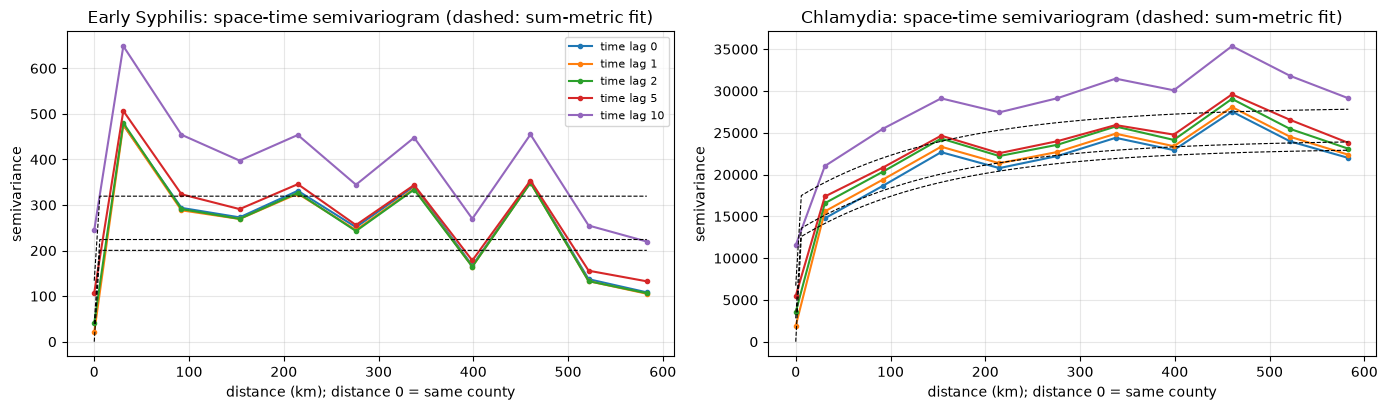

In [17]:
# Empirical space-time semivariogram at selected time lags, with the sum-metric fit drawn on top.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, d_ in zip(axes, ["Early Syphilis", "Chlamydia"]):
    df = pd.DataFrame(EMP[d_])
    for tl in [0, 1, 2, 5, 10]:
        s = df[df["timelag"] == tl].sort_values("dist")
        ax.plot(s["dist"], s["gamma"], "o-", ms=3, label=f"time lag {tl}")
    fm = STFIT[(d_, "sum-metric")]
    hh = np.linspace(0, df["dist"].max(), 100)
    for tl in [0, 1, 5]:
        surf = variogram_surface(fm, {"spacelag": hh, "timelag": np.full_like(hh, tl)})
        ax.plot(hh, surf["gamma"], "k--", lw=0.8)
    ax.set_xlabel("distance (km); distance 0 = same county"); ax.set_ylabel("semivariance")
    ax.set_title(f"{d_}: space-time semivariogram (dashed: sum-metric fit)")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Predicting 2021 from 2001-2020:


pop-weighted MSE  pop-weighted ME
disease        method                                                                 
Early Syphilis ST-PK (sum-metric)                               107.6             -6.4
               2020 rate                                         83.7             -5.5
               2020 rate x statewide 2019-20 change             132.0             -8.5
Chlamydia      ST-PK (sum-metric)                              2349.2            -20.6
               2020 rate                                       2455.7            -37.8
               2020 rate x statewide 2019-20 change           25128.1           -151.4

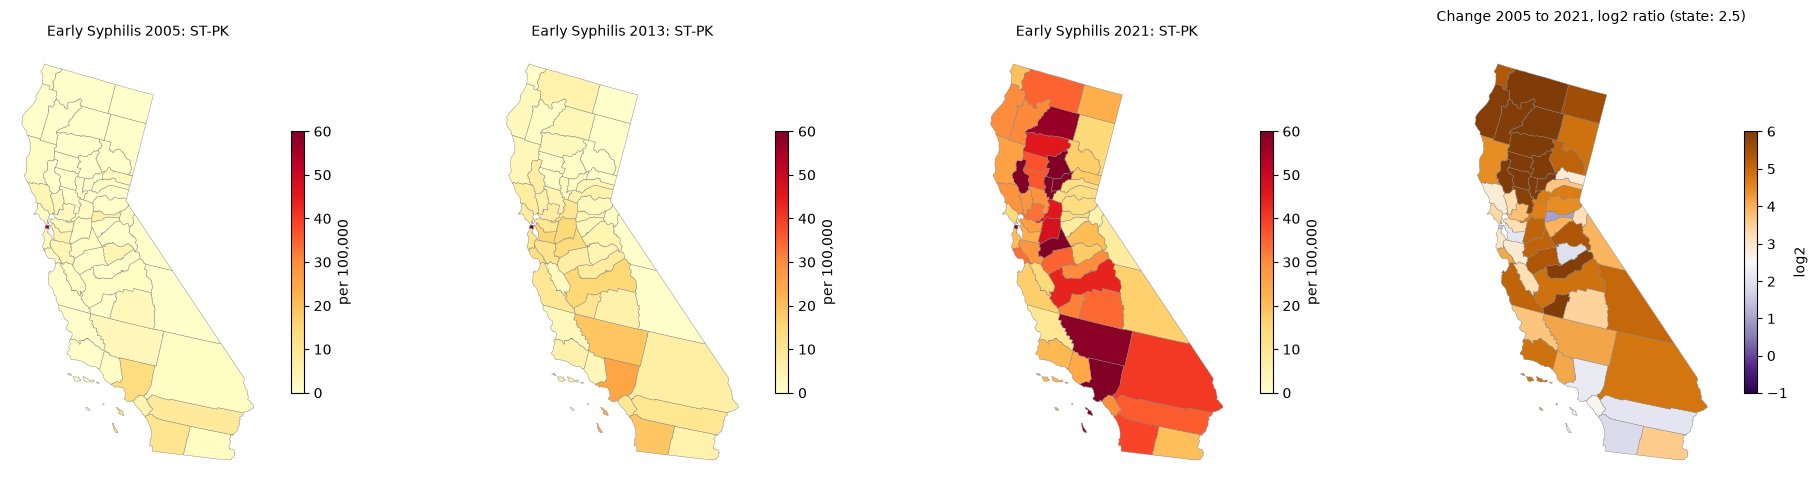

In [18]:
# Forecast-style test: predict 2021 using only 2001-2020
rows = []
for d_ in ["Early Syphilis", "Chlamydia"]:
    long, _ = ST[d_]
    tr, te = long[long["year"] < 2021], long[long["year"] == 2021]
    stpk = STPoissonKriging(STFIT[(d_, "sum-metric")], rate_base=B, use_gpu=False).fit(
        tr[["x", "y"]].to_numpy(), tr["year"].to_numpy(float), tr["rate"].to_numpy(), tr["pop"].to_numpy(), ids=tr["fips"].to_numpy())
    z, _ = stpk.predict(te[["x", "y"]].to_numpy(), te["year"].to_numpy(float), number_of_neighbors=K_ST)
    # Two simple forecasts of 2021: carry 2020 forward, and scale it by the statewide change from 2019 to 2020.
    prev = tr[tr["year"] == 2020]["rate"].to_numpy()
    change = state.loc[2020, d_] / state.loc[2019, d_]          # statewide change 2019 to 2020
    trend = prev * change
    for nm, p in [("ST-PK (sum-metric)", z), ("2020 rate", prev), ("2020 rate x statewide 2019-20 change", trend)]:
        e = p - te["rate"].to_numpy()
        rows.append({"disease": d_, "method": nm, "pop-weighted MSE": np.average(e ** 2, weights=te["pop"]),
                     "pop-weighted ME": np.average(e, weights=te["pop"])})
print("Predicting 2021 from 2001-2020:")
display(pd.DataFrame(rows).set_index(["disease", "method"]).round(1))

# Smoothed early syphilis maps for three years (each county-year keeps its own data)
d_ = "Early Syphilis"
long, _ = ST[d_]
stpk_all = STPoissonKriging(STFIT[(d_, "sum-metric")], rate_base=B, use_gpu=False).fit(
    long[["x", "y"]].to_numpy(), long["year"].to_numpy(float), long["rate"].to_numpy(), long["pop"].to_numpy(), ids=long["fips"].to_numpy())
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, yr in zip(axes[:3], [2005, 2013, 2021]):
    z, _ = stpk_all.predict(XY, np.full(len(FIPS), float(yr)), number_of_neighbors=K_ST)
    county_map(ax, z, f"{d_} {yr}: ST-PK", vmin=0, vmax=60, label="per 100,000")
# Log2 change from 2005 to 2021. The diverging scale is centred on the statewide change.
z05, _ = stpk_all.predict(XY, np.full(len(FIPS), 2005.0), number_of_neighbors=K_ST)
z21, _ = stpk_all.predict(XY, np.full(len(FIPS), 2021.0), number_of_neighbors=K_ST)
state_change = np.log2(state.loc[2021, d_] / state.loc[2005, d_])
county_map(axes[3], np.log2(np.clip(z21, 0.5, None) / np.clip(z05, 0.5, None)),
           f"Change 2005 to 2021, log2 ratio (state: {state_change:.1f})", "PuOr_r",
           norm_=TwoSlopeNorm(state_change, -1, 6), label="log2")
plt.tight_layout(); plt.show()

**Reading the results.**

- **The zero-distance bin is essential.** With the original binning, the metric model gives a population-weighted LOO MSE of 366 for early syphilis and 22,999 for chlamydia, no better than spatial PK of each year (400 and 22,953). With same-county pairs in their own bin, every fitted model cuts the error by an order of magnitude. The semivariogram plot shows why: at distance 0 the semivariance is 20 to 250, against 300 to 650 for the nearest other counties.
- **Sum-metric is the best space-time model** (19.3 for early syphilis and 1,015 for chlamydia). It beats the previous year's rate (30.1 and 2,612). For chlamydia it also beats the mean of the previous and next year (1,471), but for early syphilis that simple interpolation is still better (15.2). The strong upward trend favours the two-sided temporal neighbours.
- **Forecasting 2021 is harder.** For chlamydia, ST-PK predicts 2021 better than the 2020 rate (2,308 against 2,456). For early syphilis it is worse (108 against 84). Scaling the 2020 rate by the statewide change from 2019 to 2020 is worse for both, because 2020 was a year of reduced testing during the COVID-19 pandemic.
- **Early syphilis spread from the cities to the whole state.** In 2005 the highest smoothed rates were in San Francisco, Los Angeles, San Diego and Riverside. By 2021, San Francisco was still highest, but Lake, Yuba, Stanislaus, Sutter, Butte and Kern followed Los Angeles. The statewide rate rose by a factor of about 5.6 (2^2.5) from 2005 to 2021, but the rise was more than 100-fold (log2 above 6.6) in Lake, Yuba, Sutter, Butte and Shasta, and only about 3-fold in San Francisco.

## HIV and social determinants of health

The question here is which social conditions go with HIV risk. Two analyses are used:

- **Negative binomial regression** of the 2020 to 2021 HIV counts on standardized social determinants, with log population as offset. The coefficients are rate ratios per standard deviation. A quasi-Poisson model was tried first, but its weights grow with the count, so Los Angeles alone (51,000 people living with HIV) dominates the fit and the small rural counties get extreme residuals; the negative binomial variance μ + αμ² gives the counties more equal say.
- **Spearman correlations** of the social determinants with the observed HIV rate, the leave-one-out PCK estimate of Section 5, and the regression residual. The residual is then checked for spatial pattern (correlation with the mean residual of the five nearest counties), and kriged with Poisson kriging, using the expected count as its population (so the Poisson term is 100²/E), to see whether the risk left unexplained is spatially structured.

In [19]:
# Social determinants, standardised with the mean and standard deviation of the counties where HIV is observed.
SD = {"svi_rpl_themes": "SVI overall", "svi_epl_pov150": "below 150% poverty (pctl)", "svi_epl_uninsur": "uninsured (pctl)",
      "census_non_hispanic_black": "non-Hispanic Black (%)", "census_hispanic": "Hispanic (%)",
      "census_rural": "rural (%)", "census_65_and_older": "aged 65+ (%)"}
Xs = sdoh[list(SD)].to_numpy(float)
Z = (Xs - Xs[OBS].mean(0)) / Xs[OBS].std(0)

# The offset is log population, so each slope is a rate ratio per standard deviation of that covariate.
def negbin2(y, X, offset, iters=200):
    # Negative binomial (NB2) regression by IRLS, Var(Y) = mu + alpha mu^2, alpha by the method of moments.
    Xd = np.column_stack([np.ones(len(y)), X])
    beta = np.zeros(Xd.shape[1]); beta[0] = np.log(y.sum() / np.exp(offset).sum()); alpha = 1.0
    for _ in range(iters):
        mu = np.exp(Xd @ beta + offset)
        W = mu / (1 + alpha * mu); zz = Xd @ beta + (y - mu) / mu
        beta = np.linalg.solve(Xd.T @ (W[:, None] * Xd), Xd.T @ (W * zz))
        mu = np.exp(Xd @ beta + offset)
        alpha = max(1e-8, np.sum(((y - mu) ** 2 - mu) / mu ** 2) / (len(y) - Xd.shape[1]))
    W = mu / (1 + alpha * mu)
    cov = np.linalg.inv(Xd.T @ (W[:, None] * Xd))
    return beta, np.sqrt(np.diag(cov)), mu, alpha

# Fit the counties with HIV, then compare overdispersion with and without the covariates.
yv = Yh[0][OBS]; off = np.log(pop_h[OBS])
beta, se, mu, alpha = negbin2(yv, Z[OBS], off)
reg = pd.DataFrame({"rate ratio per SD": np.exp(beta[1:]), "95% low": np.exp(beta[1:] - 1.96 * se[1:]),
                    "95% high": np.exp(beta[1:] + 1.96 * se[1:]), "z": beta[1:] / se[1:]}, index=list(SD.values()))
print(f"Negative binomial regression, {len(yv)} counties; overdispersion alpha = {alpha:.3f} "
      f"(coefficient of variation of county risk about {np.sqrt(alpha):.2f})")
display(reg.round(2))
_, _, mu0, alpha0 = negbin2(yv, np.zeros((len(yv), 0)), off)
print(f"Overdispersion without covariates: alpha = {alpha0:.3f}; share of extra-Poisson variance explained: {100 * (1 - alpha / alpha0):.0f}%")
# The covariates move together, so the rate ratios are not separate effects.
display(pd.DataFrame(np.corrcoef(Z[OBS].T), list(SD.values()), list(SD.values())).round(2))

Negative binomial regression, 56 counties; overdispersion alpha = 0.457 (coefficient of variation of county risk about 0.68)


,rate ratio per SD,95% low,95% high,z
SVI overall,1.12,0.75,1.67,0.57
below 150% poverty (pctl),0.93,0.64,1.37,-0.35
uninsured (pctl),0.94,0.72,1.21,-0.50
non-Hispanic Black (%),1.38,1.10,1.74,2.82
Hispanic (%),0.98,0.71,1.35,-0.15
rural (%),0.61,0.41,0.90,-2.46
aged 65+ (%),1.68,1.07,2.63,2.28


Overdispersion without covariates: alpha = 1.066; share of extra-Poisson variance explained: 57%


,SVI overall,below 150% poverty (pctl),uninsured (pctl),non-Hispanic Black (%),Hispanic (%),rural (%),aged 65+ (%)
SVI overall,1.00,0.81,0.47,0.17,0.55,-0.09,-0.44
below 150% poverty (pctl),0.81,1.00,0.50,-0.09,0.36,0.23,-0.18
uninsured (pctl),0.47,0.50,1.00,-0.19,0.35,0.32,-0.06
non-Hispanic Black (%),0.17,-0.09,-0.19,1.00,0.17,-0.44,-0.47
Hispanic (%),0.55,0.36,0.35,0.17,1.00,-0.48,-0.75
rural (%),-0.09,0.23,0.32,-0.44,-0.48,1.00,0.77
aged 65+ (%),-0.44,-0.18,-0.06,-0.47,-0.75,0.77,1.00


,observed HIV rate,PCK estimate (LOO),regression residual (O/E)
SVI overall,-0.10,0.42,0.20
below 150% poverty (pctl),-0.29,0.24,0.24
uninsured (pctl),-0.25,-0.01,0.33
non-Hispanic Black (%),0.50,0.56,0.02
Hispanic (%),0.03,0.27,0.17
rural (%),-0.59,-0.53,-0.04
aged 65+ (%),-0.06,-0.49,-0.10


Correlation of log residual with neighbours' mean: 0.10
Residual relative-risk variogram (nugget, partial sill, a km): (4224.2, 0.0, 6.2) nugget share 1.00


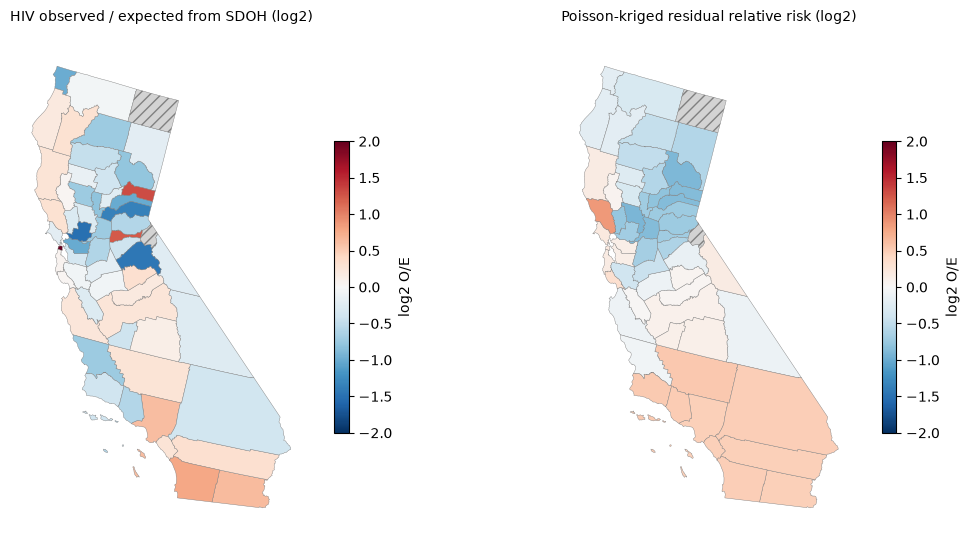

Highest and lowest O/E:


,county,O/E,HIV rate
11,Imperial,1.55,171.34
34,San Diego,1.71,391.61
1,Amador,2.33,518.17
43,Sierra,2.47,201.71
35,San Francisco,4.68,1443.17
45,Solano,0.35,269.95
52,Tuolumne,0.37,85.34
28,Placer,0.39,82.56
26,Nevada,0.49,107.14
5,Contra Costa,0.50,220.04


In [20]:
resid_rr = yv / mu                                           # observed / expected from SDOH
# Which covariates still track HIV after cokriging, and which only tracked the raw rate.
rows = {}
for j, (c, lab) in enumerate(SD.items()):
    x = Xs[OBS, j]
    rows[lab] = {"observed HIV rate": stats.spearmanr(x, Rh[0][OBS])[0],
                 "PCK estimate (LOO)": stats.spearmanr(x, SM_H[3]["rate_pred"])[0],
                 "regression residual (O/E)": stats.spearmanr(x, resid_rr)[0]}
display(pd.DataFrame(rows).T.round(2))

# Neighbour correlation of the log residual. Leftover clustering is what kriging of the residual can use.
_, nb = cKDTree(XY[OBS]).query(XY[OBS], k=6)
nbmean = np.array([np.average(np.log(resid_rr[nb[i, 1:]]), weights=pop_h[OBS][nb[i, 1:]]) for i in range(len(OBS))])
print(f"Correlation of log residual with neighbours' mean: {np.corrcoef(np.log(resid_rr), nbmean)[0, 1]:.2f}")

# Poisson kriging of the residual relative risk (expected counts as the population support)
rr100 = 100 * resid_rr                                       # percent of expected
D = pdist(XY[OBS]); ii, jj = np.triu_indices(len(OBS), 1)
g = 0.5 * (rr100[ii] - rr100[jj]) ** 2 - 0.5 * 100 * 100 * (1 / mu[ii] + 1 / mu[jj])     # Poisson noise of O/E
edges = np.arange(0, 640, 80); bins = np.digitize(D, edges) - 1
hv = np.array([D[bins == q].mean() for q in range(len(edges) - 1)]); gv = np.array([g[bins == q].mean() for q in range(len(edges) - 1)])
nv = np.array([(bins == q).sum() for q in range(len(edges) - 1)], float)
par_rr = fit_exp(hv, gv, nv)
print("Residual relative-risk variogram (nugget, partial sill, a km):", tuple(round(p, 1) for p in par_rr),
      f"nugget share {par_rr[0] / (par_rr[0] + par_rr[1]):.2f}")
pk_rr = PoissonKriging(make_variogram(par_rr, XY[OBS], rr100), rate_base=100, use_gpu=False).fit(XY[OBS], rr100, mu, ids=FIPS[OBS])
rr_s = pk_rr.predict(XY[OBS], number_of_neighbors=K_SPACE)[0]

# Observed over expected, and the same ratio after Poisson kriging, both on a log2 scale.
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
m1 = np.full(len(FIPS), np.nan); m1[OBS] = resid_rr
county_map(axes[0], np.log2(m1), "HIV observed / expected from SDOH (log2)", "RdBu_r", norm_=TwoSlopeNorm(0, -2, 2), label="log2 O/E")
m2 = np.full(len(FIPS), np.nan); m2[OBS] = rr_s / 100
county_map(axes[1], np.log2(np.clip(m2, 0.05, None)), "Poisson-kriged residual relative risk (log2)", "RdBu_r",
           norm_=TwoSlopeNorm(0, -2, 2), label="log2 O/E")
plt.tight_layout(); plt.show()
# Counties furthest above and below the count expected from the social determinants.
top = pd.DataFrame({"county": ca.loc[OBS, "name"].to_numpy(), "O/E": resid_rr, "HIV rate": Rh[0][OBS]}).sort_values("O/E")
print("Highest and lowest O/E:"); display(pd.concat([top.tail(5), top.head(5)]).round(2))

**Reading the results.**

- **Three factors stand out in the regression.** HIV prevalence is 38% higher per standard deviation of the non-Hispanic Black share (95% CI 10% to 74%) and 39% lower per standard deviation of the rural share. It is also 68% higher per standard deviation of the share aged 65 and over, but that share correlates at 0.77 with rurality and −0.75 with the Hispanic share, so this term mainly adjusts for rurality. SVI, poverty and lack of insurance add nothing once these are in the model.
- **The covariates explain 57% of the extra-Poisson variation** (α falls from 1.07 to 0.46). The remaining coefficient of variation of county risk is about 0.68.
- **Smoothing changes the picture for social vulnerability.** The observed HIV rate is unrelated to SVI (Spearman −0.10), but the PCK estimate correlates with SVI at 0.42. The STI counts carry the social gradient into the HIV estimate.
- **The residual is not spatial.** The residual relative risk correlates at 0.10 with its neighbours, and its semivariogram is pure nugget, so kriging the residual only shrinks it towards the mean. The largest residuals are San Francisco (4.7 times expected), Sierra (2.5), Amador (2.3), San Diego (1.7) and Imperial (1.6). Solano, Tuolumne, Placer, Nevada and Contra Costa have about half or less of the expected count. Isolated values such as Amador are worth checking against the populations that county counts include.

## Summary

- **Space.** County rates of chlamydia have a weak spatial structure (60% nugget, practical range about 420 km), and those of gonorrhea and early syphilis have none. Spatial Poisson kriging, centroid or area-to-area, smooths small counties but does not beat the statewide rate in population-weighted error. Area-to-point kriging gives a coherent risk surface. With the areal variogram used as a point model, area-to-area kriging over-smooths small counties and has undefined variances for the largest ones.
- **Across diseases.** HIV has no spatial structure at county level, but it correlates with gonorrhea and early syphilis. Poisson cokriging cuts the population-weighted error of HIV by 72% to 73% in leave-one-out smoothing and by 57% to 59% when HIV is hidden in 30% of counties. Its intervals are realistic, while HIV-only kriging's are far too wide. The suppressed counties, Alpine and Modoc, have estimated HIV prevalence of about 166 and 143 per 100,000.
- **Time.** County rates persist from year to year (r = 0.92). Space-time Poisson kriging uses this only after a fix to the empirical space-time variogram that keeps same-county pairs separate. With it, the leave-one-out error drops by an order of magnitude, and the sum-metric model beats last year's rate.
- **Social determinants.** HIV prevalence is higher where the Black population share is larger and lower in rural counties. The residual has no spatial pattern.
- **Package changes.** `AreaPoissonKriging.predict_area` and `predict_points` gained `exclude_self` (filtered maps), and `empirical_st_variogram` gained `zero_distance_bin`.

### Limitations

- **Uniform point support.** The county populations are spread evenly over each county, so area-to-area and area-to-point kriging see county size and shape but not where people live. With census block or tract populations, `PointSupport.from_geodataframes` builds the proper support.
- **58 areas.** Semivariograms from 58 counties are noisy, and the population-weighted estimator is dominated by a few metropolitan pairs. The fitted models carry that uncertainty, which the kriging variances do not show.
- **Surveillance data.** Reported STI cases depend on testing and reporting, which changed over 2001 to 2021 and during the COVID-19 pandemic in 2020. Part of the county pattern is a pattern of testing.
- **CHR years.** The CHR file labels its HIV data by year, but CHR releases often use data a year or two older. The 2020 to 2021 pairing with the STI counts is therefore approximate.
- **Prevalence against incidence.** HIV counts are people living with HIV, the STIs are new cases. Their joint risk in the Poisson cokriging model is a statistical device, not a measure of co-infection.
- **Ecological inference.** The social-determinant associations are between counties, not people.

### Exercises

1. Repeat Section 4 with population-weighted point support built from census tract populations. Does area-to-area kriging now beat centroid kriging?
2. Model the rates by sex: is the space-time structure of early syphilis the same for men and women?
3. Add chlamydia as a fourth variable in the HIV cokriging. Does a third STI still help?
4. Fit the space-time model to log rates or to rates relative to the statewide rate of each year, to remove the strong upward trend of early syphilis, and compare with Section 6.
5. Use the 2022 to 2025 HIV data as a panel and predict the suppressed Sierra County years with space-time Poisson kriging.
6. Replace the regression of Section 7 with regression Poisson kriging: krige the residual relative risk and add the kriged residual to the regression prediction for every county.

## References

- Goovaerts, P. (2005). Geostatistical analysis of disease data: estimation of cancer mortality risk from empirical frequencies using Poisson kriging. *International Journal of Health Geographics*, 4, 31.
- Goovaerts, P. (2006). Geostatistical analysis of disease data: accounting for spatial support and population density in the isopleth mapping of cancer mortality risk using area-to-point Poisson kriging. *International Journal of Health Geographics*, 5, 52.
- Monestiez, P., Dubroca, L., Bonnin, E., Durbec, J.-P. and Guinet, C. (2006). Geostatistical modelling of spatial distribution of Balaenoptera physalus in the Northwestern Mediterranean Sea from sparse count data and heterogeneous observation efforts. *Ecological Modelling*, 193, 615-628.
- Payares-Garcia, D., Osei, F., Mateu, J. and Stein, A. (2024). Multivariate Poisson cokriging: a geostatistical model for health count data. *Statistical Methods in Medical Research*, 33(9), 1637-1659.
- Pebesma, E. (2012). spacetime: spatio-temporal data in R. *Journal of Statistical Software*, 51(7).